# Hälsostudie Del 1


## Introduktion 

Den här notebooken analyserar data från en hälsostudie med 800 deltagare. Datasetet innehåller infomation om ålder, kön, längd, vikt, systoliskt blodtryck, kolesterol, rökvanor och sjukdom. 

Syftet är att sammanfatta deltagarnas hälsodata med statistik och diagram. Analysen undersöker också andelen deltagare med sjukdomen, beräknar konfidensintervall för medelblodtrycket och testar om rökare har högre medelblodtryck än icke-rökare. En simulering används för att undersöka hur ofta testet upptäcker olika tänkta skillnader.


### Import


In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import os 
import numpy as np 
from pathlib import Path
from matplotlib.ticker import PercentFormatter
from scipy import stats

### Läs in datasetet 

In [2]:
filnamn = "health_study_dataset.csv"
arbetsmapp = Path.cwd().resolve()

möjliga_filer = [
    mapp / "data" / filnamn
    for mapp in [arbetsmapp, *arbetsmapp.parents]
]

csv_fil = next((fil for fil in möjliga_filer if fil.exists()), None)

if csv_fil is None:
    raise FileNotFoundError(
        f"Hittade inte {filnamn} i någon data-mapp. "
        f"Notebookens arbetsmapp är: {arbetsmapp}"
    )

df = pd.read_csv(csv_fil)

huvudmapp = csv_fil.parent.parent
bilder_mapp = huvudmapp / "bilder"
bilder_mapp.mkdir(exist_ok=True)

print(f"Läste in filen: {csv_fil}")
print(f"Antal rader och kolumner: {df.shape}")
print(f"Bilder sparas i: {bilder_mapp}")

Läste in filen: C:\Users\PC\Desktop\Hälsostudie Del 1\data\health_study_dataset.csv
Antal rader och kolumner: (800, 9)
Bilder sparas i: C:\Users\PC\Desktop\Hälsostudie Del 1\bilder


### Datakontroll

In [3]:

print("Antal deltagare och variabler:", df.shape)

print("\nSaknade värden:")
print(df.isna().sum())

print("\nAntal dubblettrader:", df.duplicated().sum())

variabler = ["age", "weight", "height", "systolic_bp", "cholesterol"]
print("\nDatatyper:")

print(df[variabler].dtypes)

Antal deltagare och variabler: (800, 9)

Saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Antal dubblettrader: 0

Datatyper:
age              int64
weight         float64
height         float64
systolic_bp    float64
cholesterol    float64
dtype: object


### Beskrivande analys
Ålder, vikt, längd, systoliskt blodtryck och kolesterol sammanfattas med medelvärde, median, minimi- och maximivärde. Det ger en bild av datans nivå och spridning. 

In [4]:
variabler = ["age", "weight", "height", "systolic_bp", "cholesterol"]

sammanfattning = df[variabler].agg(["mean", "median", "min", "max"]).T

sammanfattning = sammanfattning.rename(
    index={
        "age": "Ålder (år)",
        "weight": "Vikt (kg)",
        "height": "Längd (cm)",
        "systolic_bp": "Systoliskt blodtryck (mmHg)",
        "cholesterol": "Kolesterol (mmol/L)",
    },
    columns={
        "mean": "Medelvärde",
        "median": "Median",
        "min": "Min",
        "max": "Max",
    },
)

sammanfattning.round(2)

,Medelvärde,Median,Min,Max
Ålder (år),49.43,50.00,18.0,90.00
Vikt (kg),73.41,73.20,33.7,114.40
Längd (cm),171.85,171.35,144.4,200.40
Systoliskt blodtryck (mmHg),149.18,149.40,106.8,185.90
Kolesterol (mmol/L),4.93,4.97,2.5,7.88


### Resultat och tolkning 

För alla fem variabler ligger medelvärde och median nära varandra, vilket tyder på ganska jämna och symmetriska fördelningar. Medelvärdet för systoliskt blodtryck
är 149,18 mmHg och medianen är 149,40 mmHg. Deltagarans ålder sträcker sig från 18 till 90 år, med ett medelvärde på 49,43 år. 
Minimi- och maximivärdena ser rimliga ut, och ingen uppenbara felaktiga värden syns i tabellen. 

### 1. Histogram över systoliskt blodtryck

Ett histogram delar in blodtrycksvärdena i intervall. Stapelhöjden visar hur många deltagare som har värden i varje intervall. 

I diagrammet syns också: 
- **Den böjda linjen** visar fördelnings form, alltså var värdena ligger tätast. 
- **Den streckade linjen** markerar medelvärdet, 149,2 mmHg. 
- **Det gula området** markerar det centrala området, 135-167 mmHg.


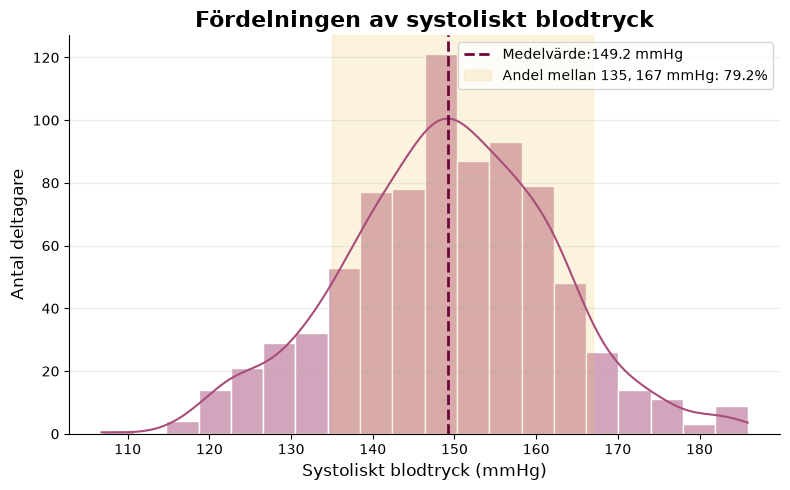

In [5]:
blodtryck = df["systolic_bp"].dropna()
andel_i_området = blodtryck.between(135, 167).mean()

plt.figure(figsize=(8,5))

sns.histplot(
    data=df, 
    x="systolic_bp", 
    bins=20, 
    kde=True,
    color="#A84C7A",
    edgecolor="white",
    linewidth=1
)

medel=df["systolic_bp"].mean()
plt.axvline(
    medel, 
    color="#6E043F", 
    linestyle="--", 
    linewidth=2,
    label=f"Medelvärde:{medel:.1f} mmHg"
)

plt.axvspan(
    135, 167, 
    color="#F2C14E", 
    alpha=0.18,
    label=f"Andel mellan 135, 167 mmHg: {andel_i_området:.1%}"
)

plt.title("Fördelningen av systoliskt blodtryck", fontsize=16, weight="bold")
plt.xlabel("Systoliskt blodtryck (mmHg)", fontsize=12)
plt.ylabel("Antal deltagare", fontsize=12)
plt.legend()
plt.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()

plt.savefig(bilder_mapp / "blodtryck_histogram.png", dpi=150, bbox_inches="tight")
plt.show()


### Resultat och tolkning 

Histogramet visar att deltagarnas systoliska blodtryck främst är koncentrerat kring 150mmHg. 79,2 % av deltagarna hade ett blodtryck mellan 135 och 167 mmHg.
Färre deltagare hade värden utanför detta intervall. Medelvärdet var cirka 149,2 mmHg. Resultatet beskriver fördelningen i det här datasetet. 

### Boxplot över vikt per kön 

Boxploten jämför viktfördelningen mellan kvinnor och män.
- **Strecket i lådan** är medianen, alltså mittvärdet. 
- **Lådan** innehållet de mittersta 50% av deltagarna. 
- **Linjen ut från lådan** sträcker sig till de yttersta värden som inte räknas som extremvärden enligt boxplotens regel.
- **De mörka prickarna** visar enskild deltagares vikt, Prickarna sprids lite i sidled för att de ska synas, sidledens position har ingen betydelse. 
- **De turkosa prickarna** markerar värden som ligger ovanligt långt i från resten enligt regeln 1,5 gånger lådans spridning. De är ovanliga värden, men behöver inte vara felaktiga


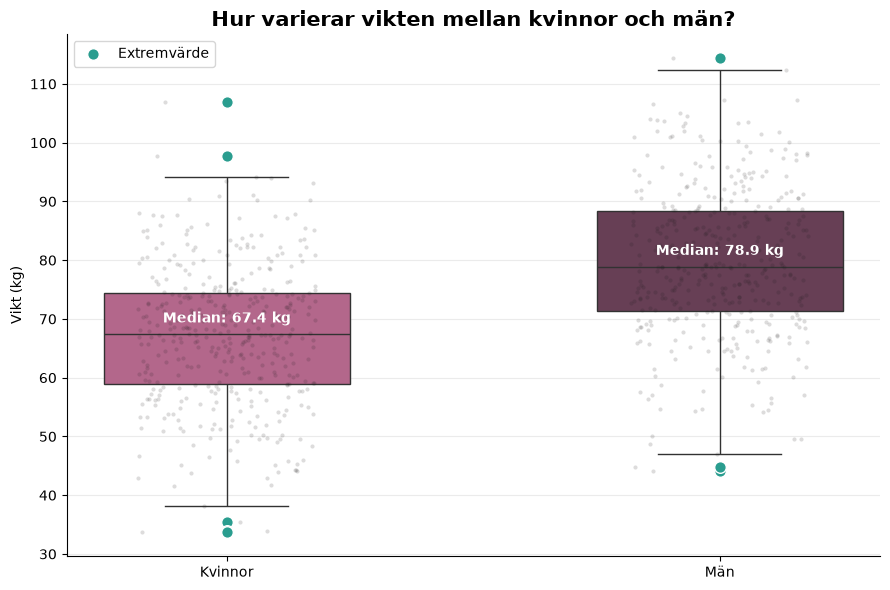

In [6]:
df["kön_namn"] = df["sex"].map({"F": "Kvinnor", "M": "Män"})
ordning = ["Kvinnor", "Män"]

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="kön_namn",
    y="weight",
    hue="kön_namn",
    order=ordning,
    palette=["#C05A8A", "#6E3856"],
    width=0.5,
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=df,
    x="kön_namn",
    y="weight",
    order=ordning,
    color="#1B1A1A",
    alpha=0.15,
    size=3,
    jitter=0.18,
    ax=ax
)

def hitta_extremvärden(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return serie[(serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)]

medianer = df.groupby("kön_namn")["weight"].median()

for position, grupp in enumerate(ordning):
    värden = df[df["kön_namn"] == grupp]["weight"]
    extrema = hitta_extremvärden(värden)

    ax.scatter(
        np.full(len(extrema), position),
        extrema,
        color="#2A9D8F",
        edgecolor="white",
        linewidth=1,
        s=70,
        zorder=5,
        label="Extremvärde" if position == 0 else None
    )

    ax.text(
        position,
        medianer[grupp] + 2,
        f"Median: {medianer[grupp]:.1f} kg",
        ha="center",
        fontsize=10,
        weight="bold",
        color="white",
        zorder=6
    )

ax.set_title("Hur varierar vikten mellan kvinnor och män?", fontsize=15, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Vikt (kg)")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left")

sns.despine()
plt.tight_layout()

plt.savefig(bilder_mapp / "vikt_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### Resultat och tolkning 

I datasetet är medianvikten högre bland män än bland kvinnor. Vikterna varierar inom båda grupperna och fördelningen överlappar, Diagrammet visar inte att varje man väger mer än varje kvinna. Resultatet beskriver deltagarna i den här studien och visar inte vad som orsakar skillnaden. 

### Stapeldiagram över andelen rökare

Först räknar vi antalet deltagare som svarat "No" respektive "Yes". Sedan delar vi varje grupps antal med det totala antalet svar och multiplicerar med 100 för att få procent. Procentsatserna och antalen visas ovanför staplarna.

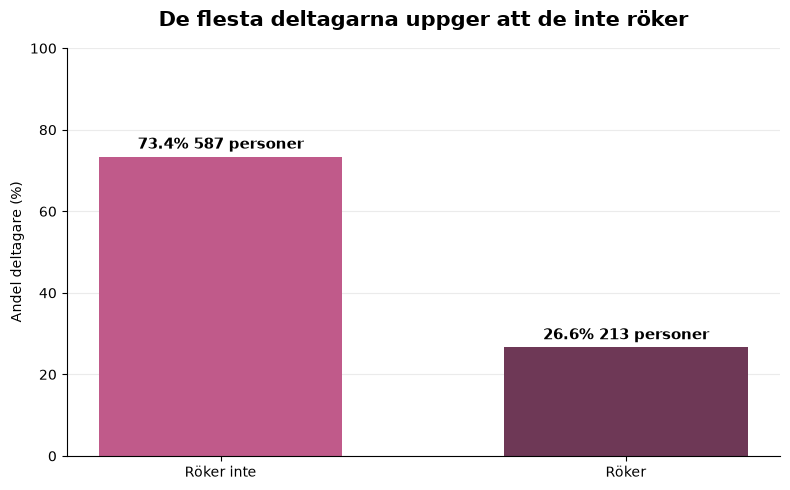

In [7]:
antal = df["smoker"]. value_counts().reindex(["No", "Yes"], fill_value=0)
procent = antal / antal.sum() * 100

namn = ["Röker inte", "Röker"]
färger =["#C05A8A", "#6E3856"]

fig, ax = plt.subplots(figsize=(8, 5))

staplar = ax.bar(
    namn,
    procent,
    color=färger,
    width=0.6
)

for stapel, pct, n in zip(staplar, procent, antal):
    ax.text(
        stapel.get_x() + stapel.get_width() / 2,
        stapel.get_height() + 2,
        f"{pct:.1f}% {n} personer",
        ha="center",
        fontsize=11,
        weight="bold" 
    )

ax.set_title("De flesta deltagarna uppger att de inte röker",
             fontsize=15, weight="bold", pad=16)
ax.set_ylabel("Andel deltagare (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(bilder_mapp / "antal_stapeldiagram.png", dpi=150, bbox_inches="tight")

plt.show()


### Resultat och tolkning 

Diagrammet visar att ungefär tre fjärdedelar av deltagarna uppger att de inte röker, medan ungefär en fjärdedel uppger att de röker. Procentsatserna gäller deltagarna i datasetet. 

### Simulering av sjukdomsandel

Först beräknas andelen deltagare med sjukdomen i datasetet. Därefter används andelen som sannolikhet när datorn simulerar 1 000 personer. Random seed gör att simuleringen går att återskapa med samma resultat. 

In [8]:
sjukdom = df["disease"].dropna()

verklig_andel = (sjukdom == 1). mean()

rng = np.random.default_rng(42)

simulerade_personer = rng.binomial(
    n=1,
    p=verklig_andel,
    size=1000
)

simulerad_andel = simulerade_personer.mean()
skillnad_pp = abs(simulerad_andel - verklig_andel) * 100

print(f"Verklig andel i datasetet: {verklig_andel:.1%}")
print(f"Simulerad andel bland 1 000 personer: {simulerad_andel:.1%}")
print(f"Skillnad: {skillnad_pp:.1f} procentenheter")

Verklig andel i datasetet: 5.9%
Simulerad andel bland 1 000 personer: 5.4%
Skillnad: 0.5 procentenheter


### Resultat och tolkning 

I datasetet hade 5,9 % av deltagarna sjukdomen. I simuleringen av 1 000 slumpade personer blev andelen 5,6% en skillnad på 0,5 procentenheter. Simuleringen hamnade alltså nära andelen i datasetet. Den lilla skillnaden beror på slumpvariation. 

### Konfidensintervall för systoliskt blodtryck 

Ett ungefärligt 95-procentigt konfidensintervall för medelvärdet beräknas med normalapproximation. Intervallet beskriver osäkerheten kring det skattade medelvärdet. Beräkningen använder stickprovets medelvärde och standardfel. Intervallet gäller medelvärdet, inte blodtrycket hos 95 % av deltagarna. 

In [9]:
blodtryck = df["systolic_bp"].dropna()

n = len(blodtryck)
medel = blodtryck.mean()
standardavvikelse = blodtryck.std(ddof=1)

standardfel = standardavvikelse / np.sqrt(n)

nedre_gräns = medel - 1.96 * standardfel
övre_gräns = medel + 1.96 * standardfel

print(f"Antal deltagare: {n}")
print(f"Medelvärde: {medel:.2f} mmHg")
print(f"95 % konfidensintervall: {nedre_gräns:.2f}--{övre_gräns:.2f}mmHg")



Antal deltagare: 800
Medelvärde: 149.18 mmHg
95 % konfidensintervall: 148.29--150.07mmHg


### Resultat och tolkning 

Medelblodtrycket bland de 800 deltagarna är 149,18 mmHg. Det 95-procentiga konfidensintervallet är 148,29 - 150,07 mmHg.
Intervallet visar hur precis medelvärdet är uppskattat. Ju smalare intervall, desto säkrare uppskattning. 
Det gäller genomsnittet, inte blodtrycket hos varje enskild deltagare. 


### Hypotesprövning

Ett ensidigt Welch t-test jämför blodtrycket hos rökare och icke-rökare. Welch-testet passar när två oberoende gruppers medelvärden ska jämföras och kräver inte att grupperna har samma spridning. Det ensidiga testet används eftersom hypotesen gäller en bestämd riktning: att rökares medelblodtryck är högre. Om en lägre nivå också hade varit relevant att upptäcka skulle ett tvåsidigt test passa bättre. 


In [10]:
rökare = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
icke_rökare = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

resultat = stats.ttest_ind(
    rökare,
    icke_rökare,
    equal_var=False,
    alternative="greater"
)

print(f"Antal rökare: {len(rökare)}")
print(f"Antal icke-rökare: {len(icke_rökare)}")
print(f"Medelblodtryck för rökare: {rökare.mean():.2f} mmHg")
print(f"Medelblodtryck för icke_rökare: {icke_rökare.mean():.2f} mmHg")
print(f"t-värde: {resultat.statistic:.3f}")
print(f"p-värde: {resultat.pvalue:.4f}")

Antal rökare: 213
Antal icke-rökare: 587
Medelblodtryck för rökare: 149.52 mmHg
Medelblodtryck för icke_rökare: 149.05 mmHg
t-värde: 0.450
p-värde: 0.3264


### Resultat och tolkning 

Rökarnas medelblodtryck var 149,52 mmHg, jämfört med 149,05 mmHg för icke-rökare. Skillnaden var liten: 0,47 mmHg. Welch t-testet gav p = 0,3264,
vilket är större än 0,05. Därför finns det inte tillräckligt statistikt stöd för att säga att rökare har högre medelblodtryck i detta dataset. 
Resultatet visar inte att grupperna är exakt lika och visar inte att rökning orsakar blodtrycksskillnad.

## VG

### Konfidensintervall med bootstrap

Bootstrap används för att räkna ut ett 95-procentigt intervall för medelblodtrycket. Datorn drar nya grupper ur blodtrycksvärdena, med återläggning. Varje grupp är lika stor som den ursprungliga.

1. Ett nytt stickprov dras. Samma värde kan väljas flera gånger.
2. Medelvärdet räknas ut. Detta upprepas 10 000 gånger.
3. De mittersta 95 % av medelvärdena bildar bootstrapintervallet.

Metoden jämförs med normalapproximationen och bygger inte på samma antagande om normalfördelade värden. Urvalet behöver ändå vara ett rimligt underlag för gruppen som resultatet ska beskriva. `default_rng(42)` gör att slumpningen kan upprepas. [NumPy-dokumentation för `Generator.choice`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)


In [11]:
rng = np.random.default_rng(42)

antal_omdragningar = 10_000

bootstrap_stickprov = rng.choice(
    blodtryck,
    size=(antal_omdragningar, len(blodtryck)),
    replace=True
)

bootstrap_medelvärden = bootstrap_stickprov.mean(axis=1)

bootstrap_nedre = np.percentile(bootstrap_medelvärden, 2.5)
bootstrap_övre = np.percentile(bootstrap_medelvärden, 97.5)

print(f"Normalapproximation: {nedre_gräns:.2f}--{övre_gräns:.2f} mmHg")
print(f"Bootstrap:           {bootstrap_nedre:.2f}--{bootstrap_övre:.2f} mmHg")



Normalapproximation: 148.29--150.07 mmHg
Bootstrap:           148.31--150.05 mmHg


### Resultat och tolkning

Normalapproximationen gav intervallet 148,29–150,07 mmHg. Bootstrap gav nästan samma intervall: 148,31–150,05 mmHg.

Medelblodtrycket bland deltagarna var 149,18 mmHg. Intervallen visar osäkerheten kring medelvärdet. De gäller genomsnittet, inte varje persons blodtryck.

## Power-simulering för hypotesprövningen

Power visar hur ofta ett test hittar en skillnad som finns. Datorn gör 1 000 låtsasstudier för varje tänkt skillnad mellan rökares och icke-rökares blodtryck. Skillnaderna i simuleringen är exempel de är inte bevis för att skillnaderna finns i verkligheten.

I varje låtsasstudie testas om rökarna har högre medelblodtryck. Power är andelen tester som hittar en skillnad. Vid 0 mmHg finns ingen skillnad inlagd. Då visar resultatet hur ofta testet ändå ger utslag av slumpen, det förväntas ligga nära 5 %.

Simuleringen visar att större skillnader är lättare för testet att hitta. Resultaten gäller de gruppstorlekar och den variation som finns i datasetet. De visar inte att rökning orsakar en skillnad.

Testet använder Welch t-test. [SciPy-dokumentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html) beskriver testet, och [NumPy-dokumentation](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html) beskriver slumpmässiga urval.


In [12]:
rng = np.random.default_rng(42)

tänkta_skillnader = [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 5]
antal_simuleringar = 1000
alpha = 0.05

power_lista = []

for skillnad in tänkta_skillnader:
    träffar = 0

    for _ in range(antal_simuleringar):
        sim_icke_rökare = rng.choice( 
            icke_rökare,
            size=len(icke_rökare),
            replace=True
        )

        sim_rökare = rng.choice(
            rökare,
            size=len(rökare),
            replace=True
        )

        sim_rökare = (
            sim_rökare
            - rökare.mean()
            + icke_rökare.mean()
            + skillnad
        )

        test = stats.ttest_ind(
            sim_rökare,
            sim_icke_rökare,
            equal_var=False,
            alternative="greater"
        )

        if test.pvalue < alpha:
            träffar += 1

    power = träffar / antal_simuleringar
    power_lista.append(power)
    if skillnad == 0:
        print(f"Ingen inlagd skillnad: falsklarm = {power:.1%}")
    else:    
        print(f"Tänkt skillnad {skillnad} mmHg: power = {power:.1%}")

Ingen inlagd skillnad: falsklarm = 4.7%
Tänkt skillnad 0.5 mmHg: power = 13.6%
Tänkt skillnad 1 mmHg: power = 24.5%
Tänkt skillnad 1.5 mmHg: power = 41.3%
Tänkt skillnad 2 mmHg: power = 61.0%
Tänkt skillnad 2.5 mmHg: power = 76.4%
Tänkt skillnad 3 mmHg: power = 88.0%
Tänkt skillnad 3.5 mmHg: power = 96.4%
Tänkt skillnad 4 mmHg: power = 98.7%
Tänkt skillnad 5 mmHg: power = 100.0%


### Resultat och tolkning 

 Power-simuleringen uppskattar hur ofta testet hittar olika tänkta skillnader i blodtryck mellan rökare och icke-röckare. Testet upprepades 1000 gånger för varje skillnad. Små skillnader upptäcktes sällan: power var 13,6 % vid 0,5 mmHg och 24,5 % vid 1 mmHg. En skillnad på 5 mmHg upptäcktes nästan varje gång, med 99,9 % power. Resultaten visar testets begränsningar för dessa scenarier, men betyder inte att de tänkta skillnaderna faktiskt finns i datan. 

### Så läser du diagrammet

Diagrammet visar hur ofta Welch t-testet upptäcker olika tänkta skillnader i blodtrycket. Den streckade linjen markerar målet 80 % power. Vid 0 mmHg finns ingen inlagd skillnad punkten visar istället hur ofta testet ändå ger utslag. 

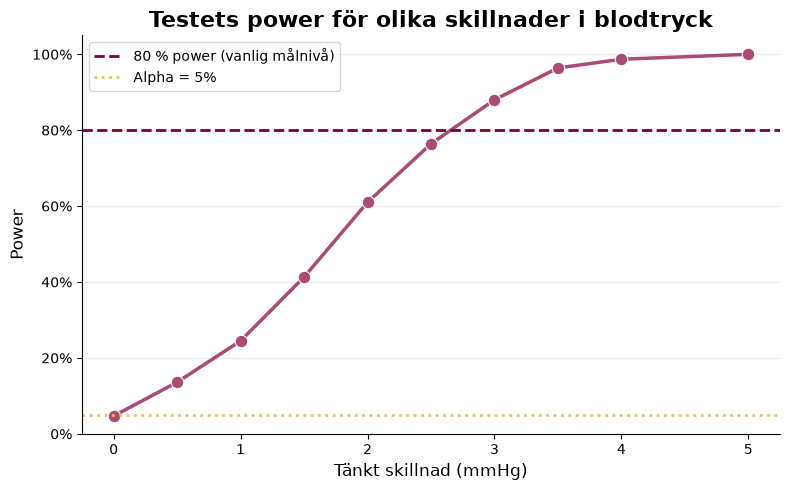

In [13]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    x=tänkta_skillnader,
    y=power_lista,
    marker="o",
    markersize=9,
    color="#A84c75",
    linewidth=2.5
)

plt.axhline(0.8, color="#6e043F", linestyle="--", linewidth=2, label="80 % power (vanlig målnivå)")
plt.axhline(alpha, color="#F2C14E", linestyle=":", linewidth=2, label=f"Alpha = {alpha:.0%}")

ax= plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.title("Testets power för olika skillnader i blodtryck", fontsize=16, weight="bold")
plt.xlabel("Tänkt skillnad (mmHg)", fontsize=12)
plt.ylabel("Power", fontsize=12)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()

os.makedirs("bilder", exist_ok=True)
plt.savefig(bilder_mapp / "power_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

### Vilken testad skillnad ger minst 80 % power?

Tabellen visar hur ofta testet hittar varje tänkt skillnad. Koden letar efter den minsta testade skillnaden där testet hittar skillnaden i minst 80 % av simuleringarna.

80 % är ett vanligt mål, men ingen fast regel. Resultatet beror på antalet deltagare och hur mycket blodtrycksvärdena varierar.

In [14]:
resultat = pd.DataFrame({
    "skillnad_mmHg": tänkta_skillnader,
    "power": power_lista
})

print(resultat)

nådde_80 = resultat[resultat["power"]>=0.8]

if not nådde_80.empty:
    första = nådde_80.iloc[0]
    print(f"\nMinsta skillnad med minst 80% power: {första['skillnad_mmHg']} mmHg")
else:
    print("\nIngen av de testade skillnaderna nådde 80% power.")

   skillnad_mmHg  power
0            0.0  0.047
1            0.5  0.136
2            1.0  0.245
3            1.5  0.413
4            2.0  0.610
5            2.5  0.764
6            3.0  0.880
7            3.5  0.964
8            4.0  0.987
9            5.0  1.000

Minsta skillnad med minst 80% power: 3.0 mmHg


### Resultat och tolkning

Testet nådde minst 80 % power vid en tänkt skillnad på 3,0 mmHg. Där var power 88,0 %. Vid 2,5 mmHg var den 76,4 %, alltså under målet.

Det betyder att testet oftare hittade större skillnader än små. Vid 1,0 mmHg hittades skillnaden i 24,5 % av simuleringarna. Ett test som inte hittar en skillnad bevisar därför inte att grupperna är exakt lika. Resultaten gäller simuleringens antaganden och är ingen exakt gräns.